# Julia から Wolfram Engine を呼び出す — 確率・統計を Julia で使う

[MathLink.jl](https://github.com/JuliaInterop/MathLink.jl) を使って Julia から Wolfram Engine を呼び出します（積分・微分・方程式・数列編の続き）。

**Wolfram の厳密な値** と **Julia の乱数シミュレーション** を並べて比べます。

- 確率 `Probability` → **厳密な分数**を受け取り，シミュレーションの相対度数と比べる
- 期待値・分散 `Expectation`, `Mean`, `Variance` → 厳密値，または文字式（$np$ など）を **Julia の関数**にする
- 確率密度関数 `PDF`，分布関数 `CDF` → **Julia の関数**にして，ヒストグラムに重ねる
- 二項分布の正規近似，信頼区間
- 数式は $\LaTeX$ 組版（TraditionalForm 相当）で表示する

**注意**：無料版 Wolfram Engine は同時に起動できるカーネル数に上限があります。他のノートブックや `wolframscript` が動いたままだと接続に失敗するので，使い終わったカーネルは停止してください。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。初回だけパッケージを追加します（追加済みなら次のセルは実行不要）。

In [1]:
# import Pkg; Pkg.add(["MathLink", "SpecialFunctions", "Distributions", "Plots"])
# Pkg.add(url="https://github.com/ujimushi/PlotsGRBackendFontJaEmoji.jl")   # グラフの日本語表示用

In [2]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数（表示・変換）
using Distributions       # Julia の確率分布（乱数・検算用）
using Statistics, Random
using Plots
using PlotsGRBackendFontJaEmoji   # グラフで日本語を使えるようにする
Random.seed!(2026);       # 乱数を固定して，毎回同じ結果にする

## 1. 基本：`Probability` と `Expectation`

「$X$ が分布 `dist` に従う」は `Distributed[X, dist]` と書きます。

In [3]:
# X ~ B(5, 1/3) のとき P(X ≥ 3)
weval(W`Probability[X >= 3, Distributed[X, BinomialDistribution[5, 1/3]]]`)

W`Rational[17, 81]`

In [4]:
# さいころの目の期待値
weval(W`Expectation[X, Distributed[X, DiscreteUniformDistribution[{1, 6}]]]`)

W`Rational[7, 2]`

## 2. きれいに表示するための関数

- `prob(事象, "X" => 分布, ...)`：$P(\text{事象})$ を表示して，結果を返す
- `expect(式, "X" => 分布, ...)`：$E[\text{式}]$ を表示して，結果を返す
- `stats(分布)`：平均・分散・標準偏差を表示して，まとめて返す

In [5]:
# TeXForm の出力を見やすく整える（条件つき確率の縦棒，場合分けの「その他」）
jtex(s) = replace(s, r"\\unicode\{f3d3\}" => "\\mid ", "\\text{True}" => "\\text{その他}")

# Wolfram 言語の文字列 → 評価せずに LaTeX 文字列（入力した形のまま表示する）
texheld(s::AbstractString) = jtex(heldtex(s))

# "a, {b, c}, d" を一番外側のカンマで分ける
function splitargs(s)
    parts = String[]; depth = 0; cur = IOBuffer()
    for c in s
        c in "[{(" && (depth += 1)
        c in "]})" && (depth -= 1)
        if c == ',' && depth == 0
            push!(parts, strip(String(take!(cur))))
        else
            print(cur, c)
        end
    end
    push!(parts, strip(String(take!(cur))))
    return filter(!isempty, parts)
end

# 分布の名前 → 表示用の名前
const DISTNAME = Dict("DiscreteUniform" => "離散一様", "Uniform" => "一様", "Exponential" => "指数",
                      "Hypergeometric" => "超幾何", "Poisson" => "ポアソン", "Geometric" => "幾何",
                      "Probability" => "密度")

# 分布（Wolfram 言語の文字列）→ B(n, p)，N(μ, σ²) などの LaTeX
function disttex(dist::AbstractString)
    m = match(r"^(\w+?)Distribution\[(.*)\]$"s, strip(dist))
    m === nothing && return texheld(dist)
    name, args = m[1], splitargs(m[2])
    label = "\\text{$(get(DISTNAME, name, name))}"
    if name == "Binomial"
        label = "B"
    elseif name == "Normal"                                    # N(μ, σ²) の形にする
        label = "N"
        args = isempty(args) || args == ["0", "1"] ? ["0", "1"] : [args[1], "($(args[2]))^2"]
    end
    return replace(texheld("f[$(join(args, ", "))]"), r"^f" => label; count=1)
end

# "X" => 分布, ... を Wolfram と LaTeX の書き方にする
wdist(vd)   = "{" * join(("Distributed[$v, $d]" for (v, d) in vd), ", ") * "}"
texdist(vd) = join(("$v \\sim " * disttex(d) for (v, d) in vd), ",\\ ")

# 確率 P(事象)
function prob(event::AbstractString, vd::Pair...)
    res = weval(MathLink.parseexpr("Probability[$event, $(wdist(vd))]"))
    showtex("P\\left(" * texheld(event) * "\\right) = " * jtex(tex(res)) * "\\qquad \\left(" * texdist(vd) * "\\right)")
    return res
end

# 期待値 E[式]
function expect(expr::AbstractString, vd::Pair...)
    res = weval(W"Simplify"(MathLink.parseexpr("Expectation[$expr, $(wdist(vd))]")))
    showtex("E\\left[" * texheld(expr) * "\\right] = " * jtex(tex(res)) * "\\qquad \\left(" * texdist(vd) * "\\right)")
    return res
end

# 平均・分散・標準偏差
function stats(dist::AbstractString; var="X")
    m = weval(MathLink.parseexpr("Mean[$dist]"))
    v = weval(MathLink.parseexpr("Variance[$dist]"))
    s = weval(MathLink.parseexpr("StandardDeviation[$dist]"))
    showtex("$var \\sim " * disttex(dist) * ":\\qquad E[$var] = " * tex(m) * ",\\quad V[$var] = " * tex(v) *
            ",\\quad \\sigma[$var] = " * tex(s))
    return (mean=m, var=v, sd=s)
end

stats (generic function with 1 method)

In [6]:
prob("X >= 3", "X" => "BinomialDistribution[5, 1/3]")
expect("X", "X" => "DiscreteUniformDistribution[{1, 6}]")
stats("BinomialDistribution[n, p]");

## 3. Wolfram の式を Julia の式・関数に変換する

変換の関数は，共通ファイル `wolfram_common.jl` にまとめてあります（0 節の `include` で読み込み済み）。

- `to_expr(w)`：Wolfram の式 → Julia の式（`Expr`）
- `to_value(w)`：Wolfram の式 → Julia の値
- `to_function(w, :x, ...)`：Wolfram の式 → Julia の関数
- 対応表 `WFUNC`（Wolfram の関数名 → Julia の関数名）に無い関数が出てきたら，`WFUNC["名前"] = :Juliaの関数名` で追加できます。

このノートブックで特に使う変換：

- 場合分け `Piecewise` → Julia の条件式（`条件 ? 値 : それ以外`）。確率密度関数は場合分けで返ることが多い
- 不等号 → Julia の比較式
- 誤差関数 `Erf`, `Erfc` とその逆関数（正規分布の確率・分位点に現れる）
- 整数や分数を入れたら厳密な分数で返る

## 4. さいころ：確率・期待値とシミュレーション

さいころ 1 個の目は，$\{1,\dots,6\}$ 上の離散一様分布です。

In [7]:
dice = "DiscreteUniformDistribution[{1, 6}]"

st = stats(dice)
to_value(st.mean), to_value(st.var)          # Julia では厳密な分数

(7//2, 35//12)

In [8]:
# シミュレーション：10 万回振る
rolls = rand(1:6, 100_000)
@show mean(rolls) Float64(to_value(st.mean))
@show var(rolls)  Float64(to_value(st.var));

mean(rolls) = 3.51024
Float64(to_value(st.mean)) = 3.5
var(rolls) = 2.9158843012430133
Float64(to_value(st.var)) = 2.9166666666666665


**大数の法則**：振る回数を増やすと，標本平均が期待値 $\frac72$ に近づきます。

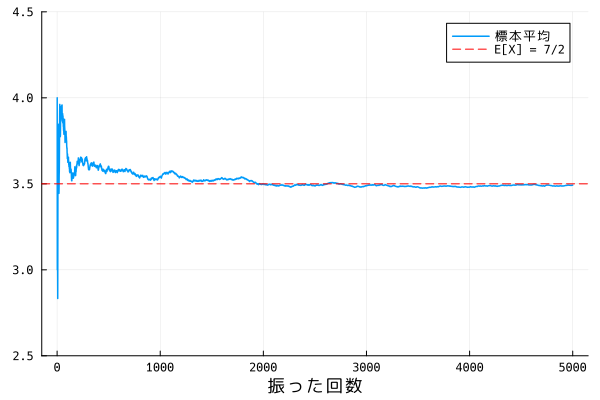

In [9]:
running = cumsum(rolls) ./ (1:length(rolls))
plot(running[1:5000]; label="標本平均", xlabel="振った回数", lw=1.5, ylims=(2.5, 4.5))
hline!([to_value(st.mean)]; color=:red, ls=:dash, label="E[X] = 7/2")

### 2 個のさいころの和

変数を 2 つ渡すと，独立な 2 つの確率変数として扱われます。

In [10]:
p7 = prob("X + Y == 7", "X" => dice, "Y" => dice)
prob("X + Y >= 10", "X" => dice, "Y" => dice)
prob("X Y >= 12", "X" => dice, "Y" => dice)
expect("X + Y", "X" => dice, "Y" => dice)
expect("X Y", "X" => dice, "Y" => dice)
to_value(p7)

1//6

In [11]:
# 和 s = 2,...,12 の確率分布（厳密な分数の配列）
distw = weval(MathLink.parseexpr("Table[Probability[X + Y == s, {Distributed[X, $dice], Distributed[Y, $dice]}], {s, 2, 12}]"))
showtex("P(X+Y=s),\\ s=2,\\dots,12:\\quad " * tex(distw))

ps = to_value(distw)
sum(ps), sum((2:12) .* ps)                   # 確率の和は 1，期待値は 7（Julia 側で厳密に計算）

(1//1, 7//1)

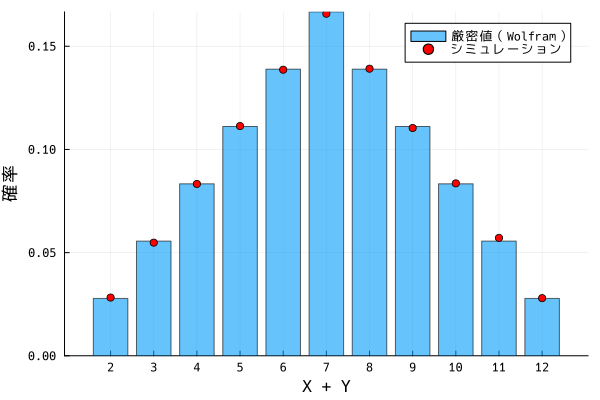

In [12]:
# シミュレーション（10 万回）の相対度数と比べる
N = 100_000
sums = rand(1:6, N) .+ rand(1:6, N)
freq = [count(==(s), sums) / N for s in 2:12]

bar(2:12, Float64.(ps); label="厳密値（Wolfram）", xlabel="X + Y", ylabel="確率", alpha=0.6, xticks=2:12)
scatter!(2:12, freq; label="シミュレーション", color=:red)

### 条件つき確率

`Conditioned[A, B]` で「$B$ のもとでの $A$」を表します。

In [13]:
prob("Conditioned[X == 6, X >= 4]", "X" => dice)
c = prob("Conditioned[X + Y >= 10, X == 6]", "X" => dice, "Y" => dice)
prob("Conditioned[X == 6, X + Y >= 10]", "X" => dice, "Y" => dice)

# シミュレーション：X = 6 だった回のうち，和が 10 以上の割合
x = rand(1:6, N); y = rand(1:6, N)
@show to_value(c) mean((x .+ y .>= 10)[x .== 6]);

to_value(c) = 1//2
mean((x .+ y .>= 10)[x .== 6]) = 0.4965928963396249


## 5. 二項分布

$X \sim B(n, p)$：1 回の成功確率 $p$ の試行を $n$ 回行ったときの成功回数。

In [14]:
bin = "BinomialDistribution[10, 1/3]"

prob("X == 3", "X" => bin)
prob("X >= 3", "X" => bin)
prob("2 <= X <= 5", "X" => bin)
stats(bin);

In [15]:
# 確率分布表（厳密な分数）と，Distributions.jl の値
pk = to_value(weval(MathLink.parseexpr("Table[PDF[$bin, k], {k, 0, 10}]")))

for k in 0:10
    println("k = $k :  ", rpad(pk[k+1], 14), Float64(pk[k+1]), "    Distributions: ", pdf(Binomial(10, 1/3), k))
end

k = 0 :  1024//59049   0.017341529915832612    Distributions: 0.01734152991583262
k = 1 :  5120//59049   0.08670764957916306    Distributions: 0.08670764957916319
k = 2 :  1280//6561    0.1950922115531169    Distributions: 0.19509221155311693
k = 3 :  5120//19683   0.2601229487374892    Distributions: 0.26012294873748987
k = 4 :  4480//19683   0.22760758014530305    Distributions: 0.22760758014530322
k = 5 :  896//6561     0.13656454808718183    Distributions: 0.13656454808718183
k = 6 :  1120//19683   0.05690189503632576    Distributions: 0.056901895036325846
k = 7 :  320//19683    0.016257684296093075    Distributions: 0.016257684296093127
k = 8 :  20//6561      0.0030483158055174516    Distributions: 0.0030483158055174477
k = 9 :  20//59049     0.0003387017561686057    Distributions: 0.0003387017561686063
k = 10 :  1//59049      1.6935087808430286e-5    Distributions: 1.6935087808430265e-5


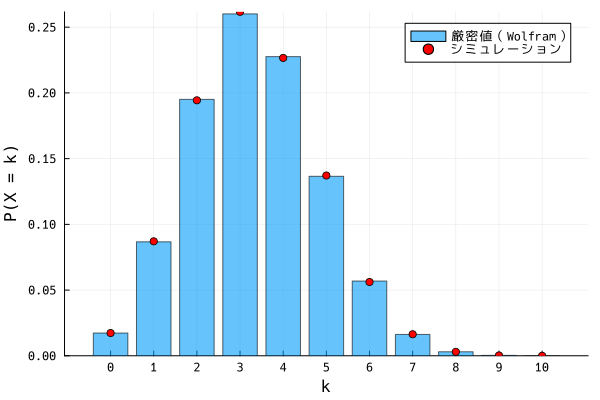

In [16]:
# シミュレーション：B(10, 1/3) に従う乱数を 10 万個
xs = rand(Binomial(10, 1/3), N)
freq = [count(==(k), xs) / N for k in 0:10]

bar(0:10, Float64.(pk); label="厳密値（Wolfram）", xlabel="k", ylabel="P(X = k)", alpha=0.6, xticks=0:10)
scatter!(0:10, freq; label="シミュレーション", color=:red)

### 文字のままの公式 → Julia の関数

$n$, $p$ を文字のままにすると，公式が返ります。これを Julia の関数にします。

In [17]:
sb = stats("BinomialDistribution[n, p]")
expect("X^2", "X" => "BinomialDistribution[n, p]")
expect("a X + b", "X" => "BinomialDistribution[n, p]")

bmean = to_function(sb.mean, :n, :p)
bvar  = to_function(sb.var,  :n, :p)
bmean(10, 1 // 3), bvar(10, 1 // 3), bvar(400, 0.5)

(10//3, 20//9, 100.0)

In [18]:
# 確率関数 P(X = k) の式（場合分けで返る）→ Julia の関数
pmfw = weval(W`PDF[BinomialDistribution[n, p], k]`)
showtex("P(X = k) = " * jtex(tex(pmfw)))

pmf = to_function(pmfw, :n, :p, :k)
to_expr(pmfw)

:(if 0 <= k <= n
      pw(1 + -p, -k + n) * pw(p, k) * binomial(n, k)
  else
      0
  end)

In [19]:
pmf(10, 1 // 3, 3), pmf(10, 1 // 3, 11), pmf(10, 0.5, 5)      # 分数を入れれば厳密，範囲外は 0

(5120//19683, 0, 0.24609375)

## 6. 連続分布：正規分布

確率密度関数 $f(x)$ を文字 $\mu$, $\sigma$ のまま求めて，Julia の関数にします。

In [20]:
fw = weval(W`PDF[NormalDistribution[μ, σ], x]`)
showtex("f(x) = " * tex(fw))

npdf = to_function(fw, :μ, :σ, :x)
npdf(0, 1, 0.0), pdf(Normal(0, 1), 0.0)       # Distributions.jl の値と一致

(0.3989422804014327, 0.3989422804014327)

In [21]:
stats("NormalDistribution[μ, σ]")
expect("(X - μ)^2", "X" => "NormalDistribution[μ, σ]")
expect("X^2", "X" => "NormalDistribution[μ, σ]")
expect("Exp[t X]", "X" => "NormalDistribution[μ, σ]");       # 積率母関数

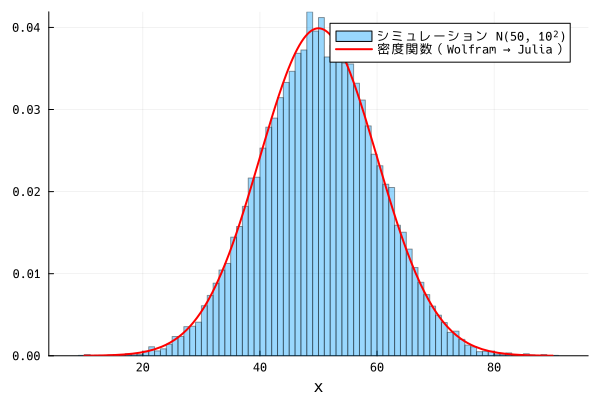

In [22]:
# 正規乱数のヒストグラムに，Wolfram から得た密度関数を重ねる
data = rand(Normal(50, 10), 20_000)
histogram(data; normalize=:pdf, label="シミュレーション N(50, 10²)", alpha=0.4, xlabel="x")
plot!(x -> npdf(50, 10, x), 10, 90; lw=2, color=:red, label="密度関数（Wolfram → Julia）")

### 正規分布の確率

確率は誤差関数 $\mathrm{erf}$ を使った厳密な式で返ります。`to_value` で数値にします。

In [23]:
Z = "NormalDistribution[0, 1]"
q1 = prob("-1 <= Z <= 1", "Z" => Z)
q2 = prob("-2 <= Z <= 2", "Z" => Z)
q3 = prob("-3 <= Z <= 3", "Z" => Z)
to_value.([q1, q2, q3])                       # 68–95–99.7 ルール

3-element Vector{Float64}:
 0.6826894921370859
 0.9544997361036416
 0.9973002039367398

In [24]:
q = prob("60 <= X <= 80", "X" => "NormalDistribution[50, 10]")

@show to_value(q)
@show cdf(Normal(50, 10), 80) - cdf(Normal(50, 10), 60)       # Distributions.jl
@show mean(60 .<= data .<= 80);                               # シミュレーション

to_value(q) = 0.15730535589982697
cdf(Normal(50, 10), 80) - cdf(Normal(50, 10), 60) = 0.15730535589982686
mean(60 .<= data .<= 80) = 0.16255


In [25]:
# 分布関数 Φ(x) = P(Z ≤ x) を Julia の関数に
Φw = weval(W`CDF[NormalDistribution[0, 1], x]`)
showtex("\\Phi(x) = " * tex(Φw))

Φ = to_function(Φw, :x)
Φ(0.0), Φ(1.96), Φ(-1.0)

(0.5, 0.9750021048517795, 0.15865525393145707)

In [26]:
# 分位点：P(Z ≤ z) = 0.975 となる z（信頼区間で使う 1.96）
zw = weval(W`Quantile[NormalDistribution[0, 1], 975/1000]`)
showtex("z_{0.975} = " * tex(zw))

z975 = to_value(zw)

1.9599639845400592

### 自分で決めた確率密度関数

$f(x) = 2x\ (0 \le x \le 1)$ のように，密度関数を直接与えることもできます（`ProbabilityDistribution`）。

In [27]:
tri = "ProbabilityDistribution[2 x, {x, 0, 1}]"

stats(tri)
r = prob("X <= 1/2", "X" => tri)
prob("1/4 <= X <= 3/4", "X" => tri)

Fw = weval(MathLink.parseexpr("CDF[$tri, x]"))
showtex("F(x) = P(X \\le x) = " * jtex(tex(Fw)))

mean(us) = 0.6676074243053001
var(us) = 0.05533697209759758
mean(us .<= 0.5) = 0.24793


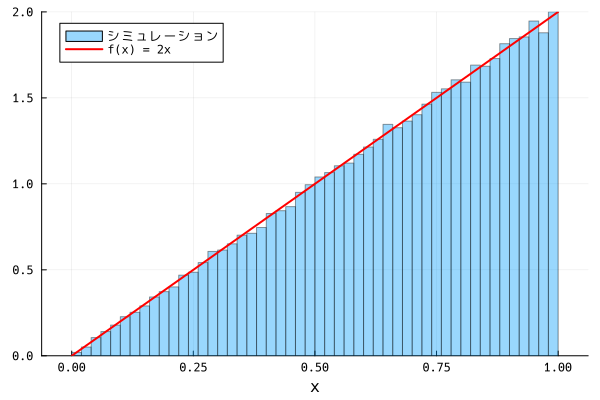

In [28]:
# シミュレーション：F(x) = x² の逆関数を使うと，X = √U（U は一様乱数）がこの分布に従う
us = sqrt.(rand(N))
@show mean(us) var(us) mean(us .<= 0.5)

histogram(us; normalize=:pdf, label="シミュレーション", alpha=0.4, xlabel="x")
plot!(x -> 2x, 0, 1; lw=2, color=:red, label="f(x) = 2x", legend=:topleft)

### 一様分布・指数分布

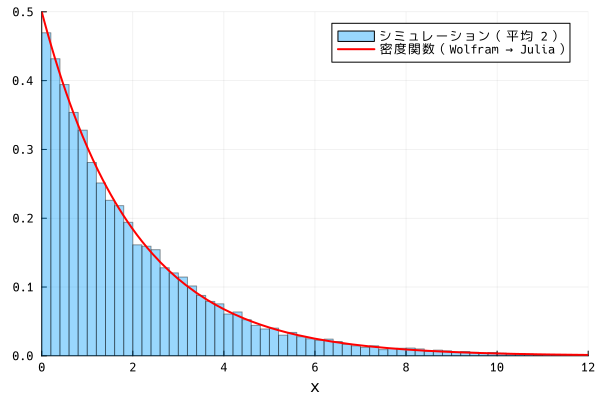

In [29]:
stats("UniformDistribution[{a, b}]")
sexp = stats("ExponentialDistribution[λ]")
prob("X > t", "X" => "ExponentialDistribution[λ]")

ew = weval(W`PDF[ExponentialDistribution[λ], x]`)
showtex("f(x) = " * jtex(tex(ew)))
epdf = to_function(ew, :λ, :x)

histogram(rand(Exponential(2), 20_000); normalize=:pdf, label="シミュレーション（平均 2）", alpha=0.4, xlabel="x", xlims=(0, 12))
plot!(x -> epdf(0.5, x), 0, 12; lw=2, color=:red, label="密度関数（Wolfram → Julia）")

## 7. 二項分布の正規近似

$n$ が大きいとき，$B(n, p)$ は $N(np,\ np(1-p))$ で近似できます。厳密な確率と比べます。

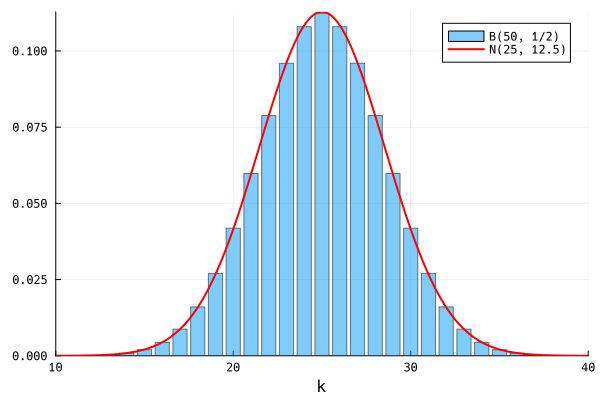

In [30]:
n, p = 50, 0.5
μ, σ = bmean(n, p), sqrt(bvar(n, p))

bar(0:n, [pmf(n, p, k) for k in 0:n]; label="B(50, 1/2)", alpha=0.5, xlabel="k", xlims=(10, 40))
plot!(x -> npdf(μ, σ, x), 10, 40; lw=2, color=:red, label="N(25, 12.5)")

In [31]:
exactw = prob("45 <= X <= 55", "X" => "BinomialDistribution[100, 1/2]")       # 厳密な分数（巨大な整数の比）
exact  = to_value(exactw)

μ, σ = bmean(100, 0.5), sqrt(bvar(100, 0.5))
@show Float64(exact)
@show Φ((55 - μ) / σ) - Φ((45 - μ) / σ)               # 正規近似
@show Φ((55.5 - μ) / σ) - Φ((44.5 - μ) / σ);          # 半整数補正つき

Float64(exact) = 0.7287469759261652
Φ((55 - μ) / σ) - Φ((45 - μ) / σ) = 0.6826894921370859
Φ((55.5 - μ) / σ) - Φ((44.5 - μ) / σ) = 0.7286678781072347


$n$ を変えて，$P(|X - \mu| \le \sigma)$ の厳密値と近似値を比べます（$p = \frac12$，$\sigma = \frac{\sqrt n}{2}$）。

In [32]:
println(rpad("n", 8), rpad("exact", 22), rpad("normal approx.", 22), "with correction")
for n in (16, 100, 400, 1600, 6400)
    μ = n ÷ 2; σ = isqrt(n) ÷ 2
    w = weval(MathLink.parseexpr("Probability[$(μ - σ) <= X <= $(μ + σ), Distributed[X, BinomialDistribution[$n, 1/2]]]"))
    exact = Float64(to_value(w))
    println(rpad(n, 8), rpad(exact, 22), rpad(Φ(1.0) - Φ(-1.0), 22), Φ((σ + 0.5) / σ) - Φ(-(σ + 0.5) / σ))
end

n       exact                 normal approx.        with correction
16      0.789886474609375     0.6826894921370859    0.7887004526662894
100     0.7287469759261652    0.6826894921370859    0.7286678781072347
400     0.7062918818382179    0.6826894921370859    0.706281887248208
1600    0.6946380674829209    0.6826894921370859    0.6946368123337793
6400    0.6887011105316784    0.6826894921370859    0.688700953306463


## 8. 推定：母比率の信頼区間

標本比率 $\hat p$ から，母比率 $p$ の 95% 信頼区間
$$\hat p - z\sqrt{\frac{\hat p(1-\hat p)}{n}} \le p \le \hat p + z\sqrt{\frac{\hat p(1-\hat p)}{n}}$$
を作ります。$z$ には 6 節で Wolfram から得た `z975`（$\approx 1.96$）を使います。

In [33]:
ci(p̂, n; z=z975) = (p̂ - z * sqrt(p̂ * (1 - p̂) / n), p̂ + z * sqrt(p̂ * (1 - p̂) / n))

# 例：400 人中 128 人が賛成
ci(128 / 400, 400)

(0.2742861771620704, 0.36571382283792964)

In [34]:
# 「95%」の意味を確かめる：真の p = 0.3 として標本調査を 10000 回くり返し，区間が p を含む割合を数える
ptrue, n, trials = 0.3, 400, 10_000
hits = count(1:trials) do _
    lo, hi = ci(rand(Binomial(n, ptrue)) / n, n)
    lo <= ptrue <= hi
end
hits / trials

0.9491

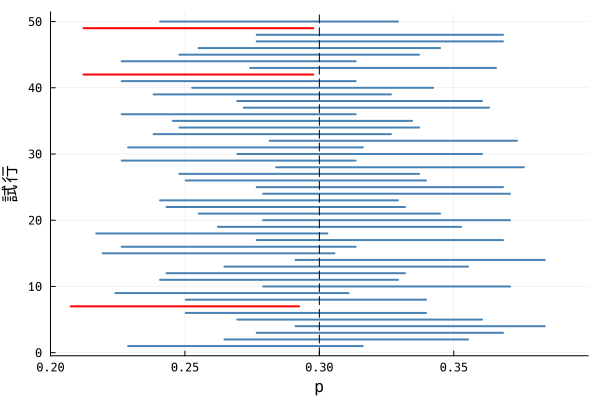

In [35]:
# 最初の 50 回分の信頼区間を図示（p を含まない区間は赤）
plot(; xlabel="p", ylabel="試行", legend=false, xlims=(0.2, 0.4))
for i in 1:50
    lo, hi = ci(rand(Binomial(n, ptrue)) / n, n)
    plot!([lo, hi], [i, i]; color=(lo <= ptrue <= hi ? :steelblue : :red), lw=2)
end
vline!([ptrue]; color=:black, ls=:dash)

## 9. うまくいかないとき

- **接続エラー（`AssertionError: nextpacket(...)` など）**：Wolfram Engine のカーネル数上限に達しています。他のノートブックのカーネルや `wolframscript` を止めてから，Julia カーネルを再起動してください。
- **大きな $n$ で `OverflowError`**：`binomial(100, 50)` などは `Int` に収まりません。`pmf(big(100), big(1) // 2, 50)` のように `big` を付けます（$n$ と $p$ の両方）。
- **等号は `==`**：事象は `X == 3`，`2 <= X <= 5` のように書きます。
- **未対応の関数が出た**：エラーメッセージに出た名前を `WFUNC` に追加します。
- **分布の名前**：`BinomialDistribution[n, p]`，`NormalDistribution[μ, σ]`（第 2 引数は**標準偏差**），`PoissonDistribution[λ]`，`HypergeometricDistribution[抽出数, 当たりの数, 全体の数]` など。

In [36]:
# 大きな n の例：Int では桁あふれするので big を使う
try
    pmf(100, 1 // 2, 50)
catch e
    println(typeof(e))
end
pmf(big(100), big(1) // 2, 50)

OverflowError


12611418068195524166851562157//158456325028528675187087900672

In [37]:
# 超幾何分布：10 本中 4 本が当たりのくじから 3 本引くとき，2 本以上当たる確率
h = prob("X >= 2", "X" => "HypergeometricDistribution[3, 4, 10]")
to_value(h), (binomial(4, 2) * binomial(6, 1) + binomial(4, 3)) // binomial(10, 3)       # 組合せで直接計算

(1//3, 1//3)